# Hafta 3 EDA: ham veri havuzu (H3-3, #20)

Sıla'nın topladığı 4 şirketlik haber/açıklama havuzu (THYAO, PGSUS, KCHOL, SAHOL). Amaç: veriyi tanımak, çıkarım ve test seti için riskleri görmek.

Çalıştırma: ham `.txt` dosyaları telif nedeniyle repoda yok, `data/ham/<ŞİRKET>/` altına Sıla'nın zip'inden açılır. Künyeler (`.json`) repoda.

## 1. Yükleme

In [1]:
import json, re, glob, os
from pathlib import Path
from collections import Counter
import pandas as pd, numpy as np
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
HAM = Path("../data/ham") if Path("../data/ham").exists() else Path("data/ham")
rows = []
for j in sorted(HAM.glob("*/*.json")):
    k = json.loads(j.read_text(encoding="utf-8"))
    t = j.with_suffix(".txt")
    k["metin"] = t.read_text(encoding="utf-8") if t.exists() else None
    rows.append(k)
df = pd.DataFrame(rows)
df["kelime"] = df["metin"].fillna("").str.split().str.len()
print("künye:", len(df), "| ham metni olan:", df["metin"].notna().sum())
print(df.groupby("sirket").size().to_string())

künye: 159 | ham metni olan: 157
sirket
KCHOL    37
PGSUS    40
SAHOL    40
THYAO    42


## 2. Kapsam: şirket ve kaynak türü

Her şirkette 37–42 sayfa var, dengeli. Haber en büyük pay (79), ardından finans portalları (46) ve resmi kaynaklar (23). Koç Holding'de resmi ve portal payı yüksek, haber az; THY'de haber ağırlıklı.

kaynak_turu
haber             79
finans_portali    46
resmi             23
ajans              7
ansiklopedi        4


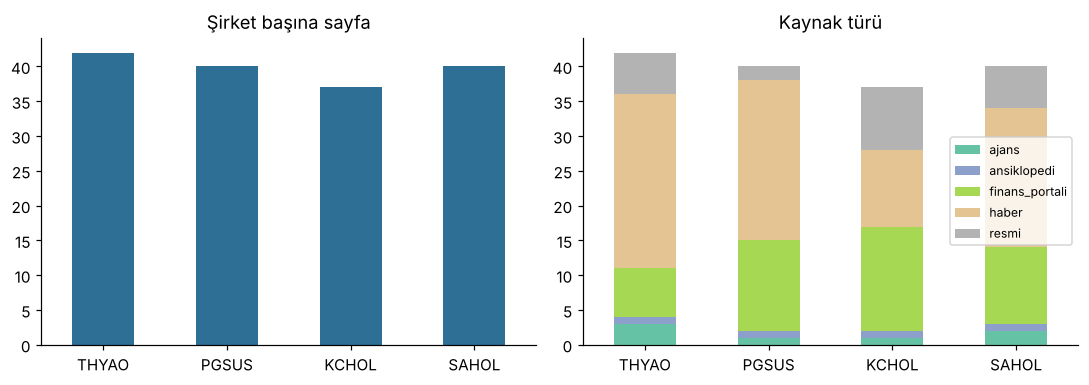

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
df.groupby("sirket").size().reindex(["THYAO","PGSUS","KCHOL","SAHOL"]).plot.bar(ax=ax[0], color="#2E6F95", rot=0)
ax[0].set_title("Şirket başına sayfa"); ax[0].set_xlabel("")
ct = pd.crosstab(df["sirket"], df["kaynak_turu"]).reindex(["THYAO","PGSUS","KCHOL","SAHOL"])
ct.plot.bar(stacked=True, ax=ax[1], rot=0, colormap="Set2"); ax[1].set_title("Kaynak türü"); ax[1].set_xlabel(""); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(df["kaynak_turu"].value_counts().to_string())

## 3. Kaynak çeşitliliği

74 farklı alan adı var ve ilk 10 alan adı havuzun yalnızca yaklaşık %35'ini oluşturuyor. Tek kaynağa bağımlılık yok, bu 'çok kaynaklı doğrulama' senaryosu için iyi.

In [3]:
top = df["alan_adi"].value_counts()
print("farklı alan adı:", len(top), "| ilk 10 alan adı toplam payı: %", round(top.head(10).sum()/len(df)*100, 1))
print(top.head(10).to_string())
print()
print("Her kaynak türünden şirket başına sayfa:")
print(ct.to_string())

farklı alan adı: 74 | ilk 10 alan adı toplam payı: % 35.2
alan_adi
fintables.com           8
aa.com.tr               7
cnbce.com               7
koc.com.tr              6
patronlardunyasi.com    5
bloomberght.com         5
ekonomim.com            5
haber.aero              5
tr.wikipedia.org        4
sabanci.com             4

Her kaynak türünden şirket başına sayfa:
kaynak_turu  ajans  ansiklopedi  finans_portali  haber  resmi
sirket                                                       
THYAO            3            1               7     25      6
PGSUS            1            1              13     23      2
KCHOL            1            1              15     11      9
SAHOL            2            1              11     20      6


## 4. Metin uzunluğu

Medyan sayfa 332 kelime, ortalama 599: dağılım sağa çarpık. 70 sayfa 300 kelimeden kısa (kısa haber), 4 sayfa 3000 kelimeden uzun (en uzunu 7412 kelime). Kısa sayfalar tek bir olguyu verir, uzun sayfalar (bilanço, genel kurul metni) çok sayıda ilişki taşır.

count     157.0
mean      599.0
std      1040.0
min        67.0
25%       222.0
50%       332.0
75%       586.0
max      7412.0
300 kelimeden kısa: 70 | 3000 kelimeden uzun: 4


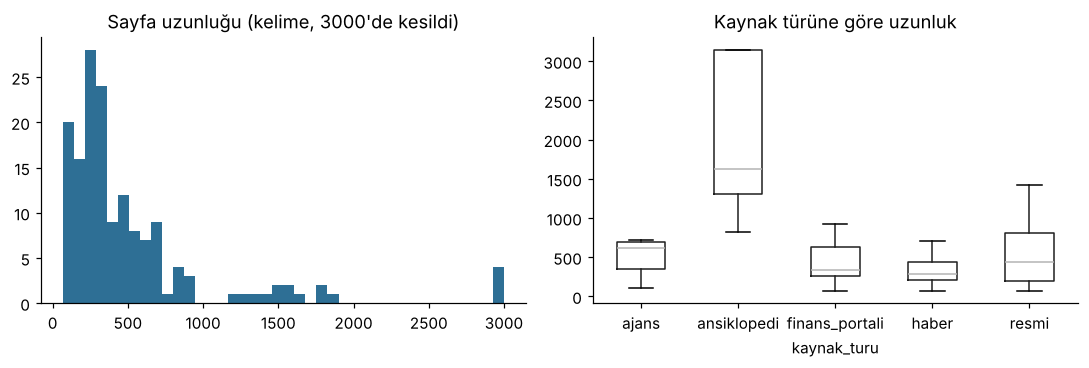

In [4]:
d = df[df["metin"].notna()]
print(d["kelime"].describe().round(0).to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(d["kelime"].clip(upper=3000), bins=40, color="#2E6F95"); ax[0].set_title("Sayfa uzunluğu (kelime, 3000'de kesildi)")
d.boxplot(column="kelime", by="kaynak_turu", ax=ax[1], showfliers=False, grid=False); ax[1].set_title("Kaynak türüne göre uzunluk"); plt.suptitle("")
plt.tight_layout(); plt.show()
print("300 kelimeden kısa:", (d["kelime"] < 300).sum(), "| 3000 kelimeden uzun:", (d["kelime"] > 3000).sum())

## 5. Model maliyeti

3000 karakterlik parça boyuyla havuz yaklaşık 297 model çağrısına denk gelir. Sayfaların %62'si tek parçaya sığar. Yerel model hızı belirlendiğinde tüm havuzu çıkarım için işlemek makul bir süredir.

In [5]:
CHUNK = 3000  # extractor.chunk_text varsayılan parça boyu (karakter)
d = d.assign(parca=np.ceil(d["metin"].str.len() / CHUNK).astype(int))
print("toplam karakter:", int(d["metin"].str.len().sum()), "| tahmini parça (model çağrısı):", int(d["parca"].sum()))
print("1 parçaya sığan sayfa: %", round((d["parca"] == 1).mean()*100, 1), "| en uzun sayfa parça sayısı:", int(d["parca"].max()))
print(d.groupby("sirket")["parca"].sum().to_string())

toplam karakter: 667180 | tahmini parça (model çağrısı): 297
1 parçaya sığan sayfa: % 61.8 | en uzun sayfa parça sayısı: 17
sirket
KCHOL    74
PGSUS    59
SAHOL    75
THYAO    89


## 6. Şirket adı geçişi

Hedef şirketin adı sayfaların %97–100'ünde geçiyor, yalnızca 2 sayfada hiç geçmiyor (ilgisiz olabilir, #19 test seti seçiminde kontrol edilecek). Isı haritasında rakip çiftlerin (THY–Pegasus, Koç–Sabancı) birbirini anma oranı görülüyor: THY ve Pegasus'un ikisi birden 10 sayfada, Koç ve Sabancı'nın 15 sayfada geçiyor: `COMPETITOR_OF` ve çok adımlı sorular için ortak sayfa var ama sayı az.

Sayfada hedef şirketin adı hiç geçmiyor: 2 sayfa
sirket
KCHOL     97.3
PGSUS    100.0
SAHOL     97.5
THYAO    100.0


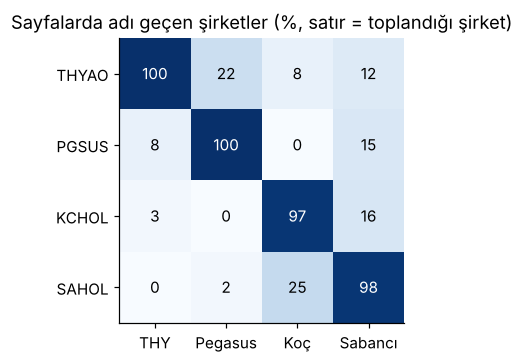

In [6]:
ADLAR = {"THY": r"türk hava yolları|\bthy\b|thyao", "Pegasus": r"pegasus|pgsus", "Koç": r"koç holding|\bkoç\b|kchol", "Sabancı": r"sabancı|sahol"}
low = d["metin"].str.lower()
for ad, rx in ADLAR.items():
    d[f"an_{ad}"] = low.str.count(rx)
ana = {"THYAO": "THY", "PGSUS": "Pegasus", "KCHOL": "Koç", "SAHOL": "Sabancı"}
d["kendi_adi_var"] = [r[f"an_{ana[r['sirket']]}"] > 0 for _, r in d.iterrows()]
print("Sayfada hedef şirketin adı hiç geçmiyor:", int((~d["kendi_adi_var"]).sum()), "sayfa")
print(d.groupby("sirket")["kendi_adi_var"].mean().mul(100).round(1).to_string())
mat = pd.DataFrame({ad: d.groupby("sirket")[f"an_{ad}"].apply(lambda s: (s > 0).mean()) for ad in ADLAR}).reindex(["THYAO","PGSUS","KCHOL","SAHOL"]) * 100
fig, ax = plt.subplots(figsize=(5.4, 3.4)); im = ax.imshow(mat.values, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(mat.columns); ax.set_yticks(range(4)); ax.set_yticklabels(mat.index)
for i in range(4):
    for j in range(4): ax.text(j, i, f"{mat.values[i,j]:.0f}", ha="center", va="center", color="white" if mat.values[i,j] > 50 else "black")
ax.set_title("Sayfalarda adı geçen şirketler (%, satır = toplandığı şirket)"); plt.tight_layout(); plt.show()

## 7. Hangi ilişkiler çıkarılabilir?

İlişki ipucu kelimeleriyle kaba bir tahmin: **yönetim kurulu / atama** THY ve Sabancı'da güçlü (%50), ortaklık/ortak girişim ipucu en çok Sabancı (%60) ve Koç'ta (%46). **Rakip** sözcüğü her şirkette sayfaların yalnızca %20–28'inde geçiyor ve Pegasus'ta iştirak ipucu çok az (%10). Sonuç: `COMPETITOR_OF` açıkça yazılmış ilişki olarak seyrek, rakiplik çoğu zaman iki ayrı sayfadan çıkarılacak. Test setindeki çok adımlı sorular bu yüzden tasarlanırken dikkat edilmeli.

İlişki ipucu kelimesi geçen sayfa oranı (%):
sirket                  THYAO  PGSUS  KCHOL  SAHOL
yönetim kurulu           50.0   35.0   43.0   50.0
atama                    52.0   25.0   30.0   35.0
iştirak/bağlı ortaklık   28.0   10.0   19.0   32.0
ortaklık/ortak girişim   28.0   15.0   46.0   60.0
rakip                    20.0   20.0   24.0   28.0
satın alma/birleşme      28.0   25.0   22.0   18.0
finansal rakam           28.0   52.0   65.0   55.0


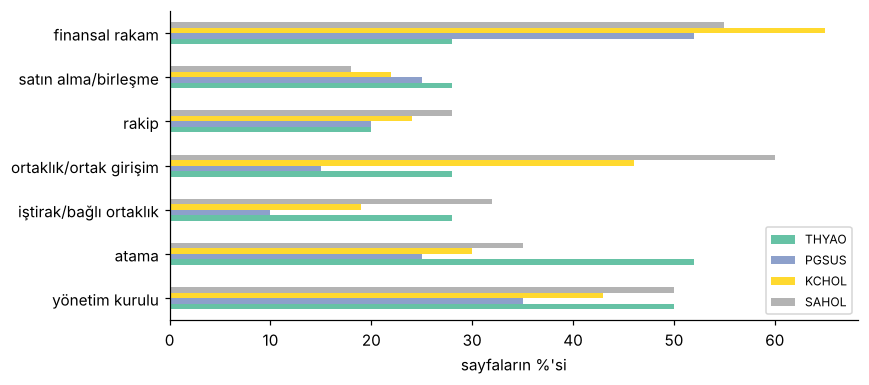

In [7]:
IPUCU = {"yönetim kurulu": r"yönetim kurulu", "atama": r"atan|atama|görevlendir", "iştirak/bağlı ortaklık": r"iştirak|bağlı ortaklık|bağlı şirket", "ortaklık/ortak girişim": r"ortak girişim|ortaklık|iş birliği|işbirliği", "rakip": r"rakip|rekabet", "satın alma/birleşme": r"satın al|devral|birleşme", "finansal rakam": r"net kâr|net kar|hasılat|bilanço|milyar|milyon"}
tab = pd.DataFrame({k: low.str.contains(rx, regex=True) for k, rx in IPUCU.items()})
tab["sirket"] = d["sirket"]
ozet = tab.groupby("sirket").mean().mul(100).round(0).reindex(["THYAO","PGSUS","KCHOL","SAHOL"])
print("İlişki ipucu kelimesi geçen sayfa oranı (%):"); print(ozet.T.to_string())
fig, ax = plt.subplots(figsize=(8, 3.6)); ozet.T.plot.barh(ax=ax, colormap="Set2"); ax.set_xlabel("sayfaların %'si"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Zaman dağılımı

Sayfaların yaklaşık %60'ı 2025 veya 2026 yılını anıyor, veri güncel. Eski yıllar (örneğin atamanın geçmişi) daha seyrek; 'geçmişte hangi firmada çalıştı' tipi sorular için kanıt sınırlı olabilir.

2025 veya 2026 geçen sayfa: % 60.5


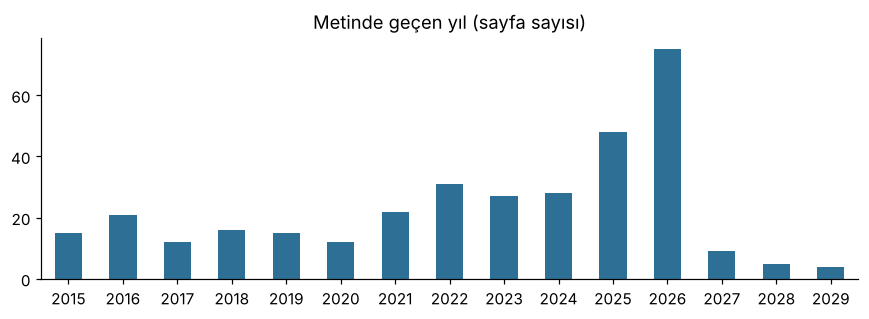

In [8]:
yil = d["metin"].str.findall(r"\b(20[12]\d)\b")
say = Counter(y for l in yil for y in set(l))
yd = pd.Series(say).sort_index()
yd = yd[yd.index >= "2015"]
fig, ax = plt.subplots(figsize=(8, 3)); yd.plot.bar(ax=ax, color="#2E6F95", rot=0); ax.set_title("Metinde geçen yıl (sayfa sayısı)"); plt.tight_layout(); plt.show()
print("2025 veya 2026 geçen sayfa: %", round(((d['metin'].str.contains('2025|2026')).mean())*100, 1))

## 9. Kalite taraması

Bozuk karakter, bot/çerez sayfası ve tekrar bulunmadı: Sıla'nın elle temizliği işe yaramış. 53 sayfa 250 kelimeden kısa; bunlar silinmemeli ama test seti için ana kaynak olarak seçilirken uzun sayfalar tercih edilmeli.

In [9]:
# Kalite taraması: kısa, bozuk karakterli, bot sayfası, tekrar
bot = r"robot olmadığ|doğrulan|captcha|erişim engel|javascript.*etkinleştir|cookie|çerez"
sorun = pd.DataFrame({
    "kısa (<250 kelime)": d["kelime"] < 250,
    "bozuk karakter": d["metin"].str.contains("Ã|Ä±|â€|\ufffd", regex=True),
    "bot/çerez ifadesi": d["metin"].str.lower().str.contains(bot, regex=True) & (d["kelime"] < 600),
})
print(sorun.sum().to_string())
ozet_t = d["metin"].str.lower().str.replace(r"\W+", " ", regex=True).str[:400]
tekrar = ozet_t.duplicated(keep=False)
print("başı birebir aynı olan sayfa:", int(tekrar.sum()), "| aynı metin özeti:", int(d["metin_sha256"].duplicated(keep=False).sum()))
print()
print("En kısa 5 sayfa:")
print(d.nsmallest(5, "kelime")[["sirket","alan_adi","kelime","baslik"]].to_string(index=False))

kısa (<250 kelime)    53
bozuk karakter         0
bot/çerez ifadesi      0
başı birebir aynı olan sayfa: 0 | aynı metin özeti: 0

En kısa 5 sayfa:
sirket         alan_adi  kelime                                                                     baslik
 THYAO airlinehaber.com      67              THY'de 4 önemli Birime Atama: Başpilot Değişti - AirlineHaber
 PGSUS       flypgs.com      73                                             Rüya, Pegasus filosuna katıldı
 SAHOL    rotaborsa.com      75 Sabancı Holding (SAHOL) 2026 yılı 3. çeyrek bilançosunu açıkladı! İşte ...
 THYAO       birgun.net      86   2.5 milyar lira sermayeli yeni şirket KAP'a bildirildi - Birgün Gazetesi
 THYAO   turizmnews.com      88                              THY'den 'SunExpress' açıklaması - Turizm News


## Sonuçlar ve sonraki adım

1. Veri temiz, dengeli ve çok kaynaklı; çıkarıma hazır.
2. 2 künyenin (KAP bildirimleri, THYAO) ham metni zip'te yok; Sıla'dan alınacak.
3. Test setinde rakiplik ve çok adımlı sorular için iki şirketten gelen sayfalar eşleştirilmeli (#19).
4. Sonraki: #22 GraphRAG baseline için ilk 40 sayfayı yerel modelle işlemek.